# Queuing systems

In this notebook, we discuss queuing systems in the discrete-event simulation context. We use a very simple example of a gas station with one pump, and cars (arriving at constant rate) lining up in front of the pump, waiting for their turn. We explore the concept of *stationary distribution* (steady-state) using Gillespie's direct method first, then we introduce a new stochastic simulation algorithm—the *event-scheduling* approach—that will allow us to simulate inter-event time for specific events that are not exponentially distributed.

In [1]:
import numpy as np
import heapq
import matplotlib.pyplot as plt
from scipy.special import gamma

## Gillespie's direct method

In [2]:
n = 1 # car already at the pump
n_traj = [n]
rng = np.random.default_rng(42)
T = 2000
alpha = 0.2 #arrival rate of cars (# cars per min)
beta = 0.3 #service rate
t = 0
t_traj = [t]

In [3]:
while t < T:
    #determine inter-event time
    service_rate = beta if n > 0 else 0
    total_rate = alpha + service_rate
    tau = rng.exponential(scale=1/(total_rate))
    t += tau
    #now we determine which event happens
    prob_arrival = alpha/(alpha + service_rate)
    if rng.random() < prob_arrival:
        n += 1
    else:
        n -= 1
    t_traj.append(t)
    n_traj.append(n)

Text(0, 0.5, 'Number of cars')

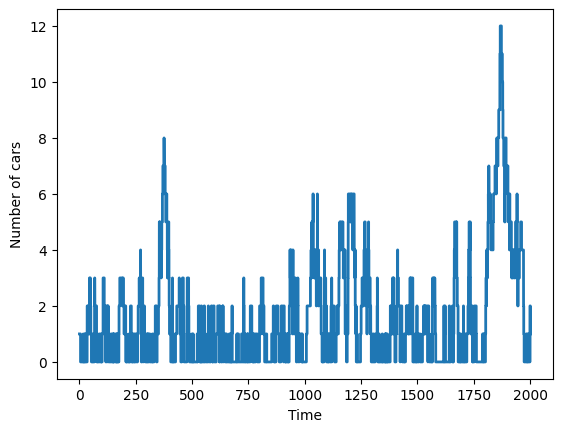

In [4]:
plt.step(t_traj, n_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of cars')

**Try these different cases:**
- check what happens when $\beta < \alpha$;
- test large initial condition ($n\gg 1$) and long time horizon $T$—what happens?

### Stationary distribution

For long time horizon, we see the trajectory oscillating around the same values, repeating itself. Let's sample this trajectory at regular time intervals of length $\Delta t = 10$ and extract the underlying distribution. We'll discard the first portion (up to $t = 200$) to only sample this "stable", long-term trajectory—this is often called a burnin or warm-up period.

**Note**: these values for the regular sampling and warm-up period have been choosen arbitrarily at this point—later we'll investigate how to guide these choices.

In [5]:
t_burn = 200
t_step = 10
n_chosen_samples = []

In [6]:
n_chosen_samples = []
for t_chosen in range(t_burn,T,t_step):
    index = np.searchsorted(t_traj,t_chosen, side='left')-1
    n_chosen_samples.append(n_traj[index])

We can also look at what theory says about this *stationary distribution*. This distribution is the fixed point of the master-equation describing the system.

In [7]:
nrange = np.arange(0,30)
rho = alpha/beta
Pn = (1-rho)*rho**nrange

mean = 1.6777777777777778  std = 2.02664351838632


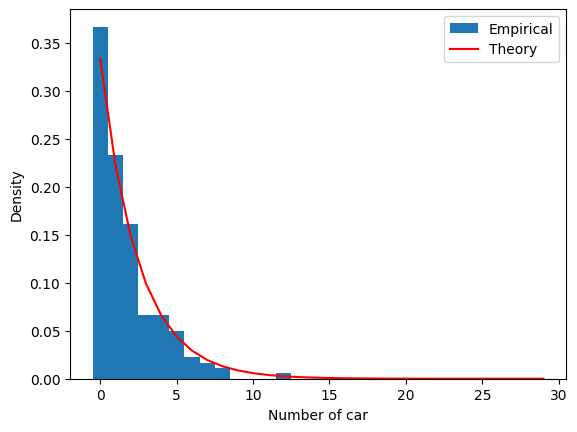

In [8]:
plt.hist(n_chosen_samples, bins=np.arange(max(n_chosen_samples)+2)-0.5, density=True, label='Empirical')
plt.plot(nrange,Pn, color='red', label='Theory')
plt.xlabel(f'Number of car')
plt.ylabel('Density')
plt.legend()
print('mean =', np.mean(n_chosen_samples), ' std =', np.std(n_chosen_samples))

The two distributions agree well. What if instead of sampling at regular intervals, we generated multiple independent trajectories and sampled at a fixed time $t^*$ far enough in the future? Would it look similar to the above?

## Event-scheduling approach

### Exponential service time

Here we investigate the alternative simulation procedure introduced in class, where we keep a *future-event list*, ordered by the time of execution of individual events. As simple verification, we consider exponential inter-event times as well, to match Gillespie's direct method.

In [9]:
T = 2000

alpha = 0.2  # arrival rate of cars (# cars per min)
beta = 0.3   # service rate

t = 0
n = 1  # one car already at the pump
t_traj = [t]
n_traj = [n]

# future event list: entries are (event time, event type)
fel = []
heapq.heappush(fel, (t + rng.exponential(1/alpha), "arrival"))
heapq.heappush(fel, (t + rng.exponential(1/beta), "departure"))  # car already being served

In [10]:
while fel and fel[0][0] < T:
    t, event = heapq.heappop(fel)  # advance to the next event

    if event == "arrival":
        n += 1
        # schedule the next arrival
        heapq.heappush(fel, (t + rng.exponential(1/alpha), "arrival"))
        # if the pump was free, the car starts service right away
        if n == 1:
            heapq.heappush(fel, (t + rng.exponential(1/beta), "departure"))

    else:  # departure
        n -= 1
        # if cars are waiting, the next one starts service
        if n > 0:
            heapq.heappush(fel, (t + rng.exponential(1/beta), "departure"))

    t_traj.append(t)
    n_traj.append(n)

Text(0, 0.5, 'Number of cars')

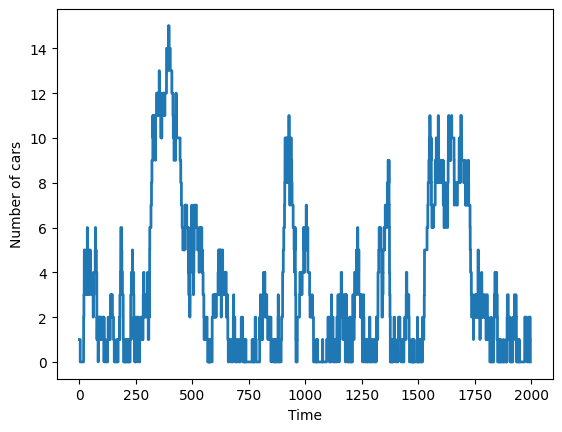

In [11]:
plt.step(t_traj, n_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of cars')

In [12]:
t_burn = 200
t_step = 10
n_chosen_samples = []

In [13]:
n_chosen_samples = []
for t_chosen in range(t_burn,T,t_step):
    index = np.searchsorted(t_traj,t_chosen, side='left')-1
    n_chosen_samples.append(n_traj[index])

In [14]:
nrange = np.arange(0,30)
rho = alpha/beta
Pn = (1-rho)*rho**nrange

mean = 3.438888888888889  std = 3.6319016887222055


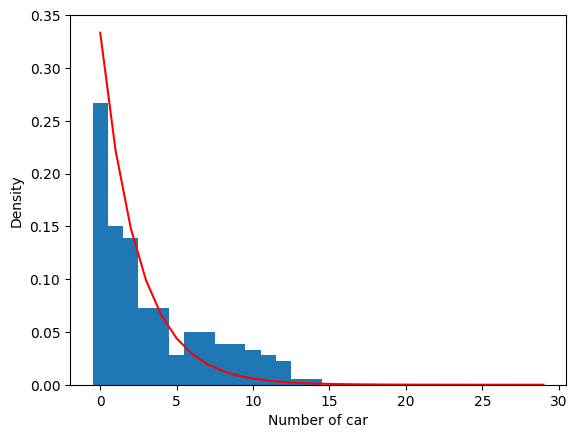

In [15]:
plt.hist(n_chosen_samples, bins=np.arange(max(n_chosen_samples)+2)-0.5, density=True)
plt.plot(nrange,Pn, color='red')
plt.xlabel(f'Number of car')
plt.ylabel('Density')
print('mean =', np.mean(n_chosen_samples), ' std =', np.std(n_chosen_samples))

Although there is variability (we don't get the same exact trajectory due to randomness), the stationary distribution appears to match.

### Weibull service time

We now consider a service time at the pump that is not exponentially distributed—we use a Weibull distribution that is more concentrated around its mean, here keeping the same mean service time.

In [16]:
k = 4.0  # Weibull shape (k = 1 gives back the exponential)
weibull_scale = (1/beta) / gamma(1 + 1/k)  # so the mean service time is 1/beta

In [17]:
T = 2000

alpha = 0.2  # arrival rate of cars (# cars per min)
beta = 0.3   # service rate

t = 0
n = 1  # one car already at the pump
t_traj = [t]
n_traj = [n]

# future event list: entries are (event time, event type)
fel = []
heapq.heappush(fel, (rng.exponential(1/alpha), "arrival"))
heapq.heappush(fel, (rng.exponential(1/beta), "departure"))  # car already being served

In [18]:
def service_time():
    return weibull_scale * rng.weibull(k)

while fel and fel[0][0] < T:
    t, event = heapq.heappop(fel)  # advance to the next event

    if event == "arrival":
        n += 1
        # schedule the next arrival
        heapq.heappush(fel, (t + rng.exponential(1/alpha), "arrival"))
        # if the pump was free, the car starts service right away
        if n == 1:
            heapq.heappush(fel, (t + service_time(), "departure"))

    else:  # departure
        n -= 1
        # if cars are waiting, the next one starts service
        if n > 0:
            heapq.heappush(fel, (t + service_time(), "departure"))

    t_traj.append(t)
    n_traj.append(n)

Text(0, 0.5, 'Number of cars')

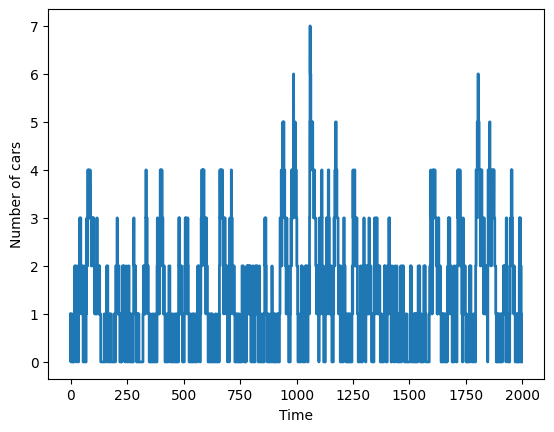

In [19]:
plt.step(t_traj, n_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of cars')

We can already see a difference in the shape of the trajectories: transient periods with a long line of car are less frequent.